# Lab Research Agent: from your question to a cited briefing

**Day 3 (agents: tools, loops and architectures)**

This morning's agent (Day3_Agent_From_Scratch) chose its tools turn by turn. Here the model **decides what to search for, which papers to read, and whether it has learned enough**, inside a loop whose order and round budget the code fixes. That is the pattern behind every "deep research" product, and you will build it in six small functions over **arXiv itself**: more than two million papers, searched live through its API, any topic, any field, up to yesterday.

```
your question ─▶ 1 plan searches (model) ─▶ 2 find candidate papers (arXiv API) ─▶ 3 select the ones worth reading (model)
              ─▶ 4 download each one, read it, summarize how it works (model) ─▶ 5 assess coverage: enough? (model) ──no──▶ back to 2
                                                                                                           └──yes, or budget used up──▶ 6 write the briefing, verify citations
```

Finding is cheap: a search returns titles and abstracts in a second. Reading is expensive: a PDF must be downloaded and extracted. So the agent finds widely, reads narrowly, and only ever reads what it chose.

### Learning objectives

- **Build** the six steps of a research agent and read what the model decided at each one.
- **Trace** a weak decision -- a paper picked for a reason it does not support -- from step 3 into the summary and the briefing.
- **Check** the output with code (real ids only, numbered citations, references written by code) and know what such checks cannot see.
- **Write** the prompts that steer it: a specific topic, an honest summary, a definition of "enough", a critic.
- *Extras, if you finish early:* the same agent as a LangGraph graph, more topics, optional code challenges.

Every exercise is a **prompt** (or a topic): replace the text that says *Write your prompt here*, run the cell, and compare
with the output above it. arXiv changes every day, so your papers will differ from ours; the notes say "in our test run"
when they describe the run we made in October 2026.

### Setup: Runtime → Change runtime type → **T4 GPU**, then run this cell

In [1]:
!pip install -q -U transformers accelerate chromadb sentence-transformers pypdf arxiv

import torch, json, re

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 79.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 37.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.1/405.1 kB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 79.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.

In [2]:
#@title Load Qwen3.5-4B (the same model in every lab)
import torch
from transformers import AutoTokenizer, AutoModelForImageTextToText

MODEL_ID = "Qwen/Qwen3.5-4B"                     # about 9 GB in float16: fits a free Colab T4
tok = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForImageTextToText.from_pretrained(
    MODEL_ID, dtype=torch.float16 if torch.cuda.is_available() else torch.float32, device_map="auto")
model.eval()
print("running on:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

config.json:   0%|          | 0.00/3.16k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 12.8MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/76.2k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/723 [00:00<?, ?it/s]

running on: Tesla T4


In [3]:
#@title chat(): the one function that talks to the model (the same in every lab)
def chat(messages, system=None, max_new_tokens=400, temperature=0.0, thinking=False, tools=None):
    """A prompt string or a list of {"role", "content"} messages -> the model's reply as text.
    system: an optional system prompt, put in front of the messages.
    temperature=0 is greedy (the same reply every time); above 0 it samples, with top_p=0.8 and top_k=20
    from the Qwen3.5 model card. thinking=True lets the model reason in <think>...</think> before answering.
    tools: tool schemas for native tool calling (the reply then may contain <tool_call> blocks)."""
    if isinstance(messages, str):
        messages = [{"role": "user", "content": messages}]
    if system:
        messages = [{"role": "system", "content": system}] + messages
    prompt = tok.apply_chat_template(messages, tools=tools, tokenize=False, add_generation_prompt=True,
                                     enable_thinking=thinking)                 # wrap in the model's own chat markup
    inputs = tok(prompt, return_tensors="pt").to(model.device)
    sampling = dict(do_sample=True, temperature=temperature, top_p=0.8, top_k=20) if temperature > 0 else dict(do_sample=False)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, pad_token_id=tok.pad_token_id, **sampling)
    return tok.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()  # keep only the new text

In [4]:
print(chat("Say hello in five words."))

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


Hello there, friend. How are you?


## 1: The source: arXiv, live

The `arxiv` package wraps arXiv's public API and respects its rate limit (one request every three seconds). A search returns metadata and the abstract for each paper; the PDF is only fetched later, for papers the agent selects. Everything the agent has seen in this session is kept in one dictionary, `PAPERS`, keyed by arXiv id.

In [5]:
import arxiv, requests, io, re, pandas as pd
from pypdf import PdfReader
from IPython.display import Markdown, display

api = arxiv.Client()                                                                   # polite by default: 3 s between requests, retries
PAPERS = {}                                                                            # id -> {title, year, authors, abstract, url, pdf, text}

def step(n, title, *lines):
    '''One banner per pipeline step, so every run reads the same way.'''
    print(f"\n{'━' * 72}\n Step {n} · {title}\n{'━' * 72}")
    for line in lines:
        print(line)

def search_arxiv(query, k=5):
    '''Ask arXiv for the k papers most relevant to a query. Returns their ids; metadata + abstract go into PAPERS.'''
    ids = []
    for r in api.results(arxiv.Search(query=query, max_results=k, sort_by=arxiv.SortCriterion.Relevance)):
        pid = r.get_short_id().split("v")[0]
        PAPERS.setdefault(pid, {"id": pid, "title": r.title.replace("\n", " "), "year": r.published.year, "authors": ", ".join(a.name for a in r.authors),
                                "abstract": r.summary.replace("\n", " "), "url": f"https://arxiv.org/abs/{pid}", "pdf": r.pdf_url, "text": None})
        ids.append(pid)
    return ids

In [6]:
search = search_arxiv                                                                  # the pipeline's source; swapped later for your own documents

for pid in search("mixture of experts inference cost", k=5):
    print(f"  {pid}  {PAPERS[pid]['year']}  {PAPERS[pid]['title'][:80]}")

  2410.17954  2024  ExpertFlow: Efficient Mixture-of-Experts Inference via Predictive Expert Caching
  2402.14800  2024  Not All Experts are Equal: Efficient Expert Pruning and Skipping for Mixture-of-
  2312.04693  2023  GraphMETRO: Mitigating Complex Graph Distribution Shifts via Mixture of Aligned 
  1806.08200  2018  Mixtures of Experts Models
  2503.03213  2025  Convergence Rates for Softmax Gating Mixture of Experts


In [7]:
first = PAPERS[next(iter(PAPERS))]                                                     # one entry; long fields shortened
for key, value in first.items():
    print(f"{key:>8}: {str(value)[:150]}{' ...' if len(str(value)) > 150 else ''}")
print(f"\n{len(PAPERS)} papers in PAPERS so far. 'text' stays None until the agent decides to read a paper.")

      id: 2410.17954
   title: ExpertFlow: Efficient Mixture-of-Experts Inference via Predictive Expert Caching and Token Scheduling
    year: 2024
 authors: Xin He, Shunkang Zhang, Kaijie Tang, Shaohuai Shi, Yuxin Wang, Zihao Zeng, Zhenheng Tang, Xiaowen Chu, Haiyan Yin, Ivor W. Tsang, Yew Soon Ong
abstract: Sparse Mixture-of-Experts (MoE) models can outperform dense large language models at similar computation by activating only a small set of experts per ...
     url: https://arxiv.org/abs/2410.17954
     pdf: https://arxiv.org/pdf/2410.17954v2
    text: None

5 papers in PAPERS so far. 'text' stays None until the agent decides to read a paper.





## 2: Reading a paper: download, extract, index

`fetch_text()` downloads the PDF once and extracts its text with `pypdf`; `read_index()` chunks that text and embeds it into a **reading index** for just the selected papers; `passages()` pulls the few chunks of one paper closest to the topic. Extraction from PDFs is imperfect (two columns, equations, footers) — this is real-world text now, not a curated dataset.

In [8]:
import chromadb
from chromadb.utils.embedding_functions import SentenceTransformerEmbeddingFunction

embedder = SentenceTransformerEmbeddingFunction(model_name="all-MiniLM-L6-v2", device="cuda")
client = chromadb.Client()

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [9]:
def fetch_text(pid):
    '''Download the PDF (once) and extract its text.'''
    paper = PAPERS[pid]
    if paper["text"] is None:
        pdf = requests.get(paper["pdf"], timeout=90).content
        text = "\n".join(page.extract_text() or "" for page in PdfReader(io.BytesIO(pdf)).pages)
        paper["text"] = re.sub(r"[ \t]+", " ", re.sub(r"-\n(?=[a-z])", "", text))     # re-join hyphenated words, collapse spaces
    return paper["text"]

def chunk(text, size=800):
    pieces, current = [], ""
    for word in text.split():
        if len(current) + len(word) > size:
            pieces.append(current.strip()); current = ""
        current += word + " "
    return pieces + [current.strip()]

def fresh_collection(name):
    '''A new, empty collection with that name (replacing any previous one).'''
    try:
        client.delete_collection(name)
    except Exception:
        pass
    return client.create_collection(name, embedding_function=embedder, metadata={"hnsw:space": "cosine"})

def read_index(ids):
    '''The reading index: chunk and embed the full text of just these papers.'''
    reading = fresh_collection("reading")
    for pid in ids:
        pieces = chunk(fetch_text(pid))
        reading.add(ids=[f"{pid}-{i}" for i in range(len(pieces))], documents=pieces, metadatas=[{"id": pid, "title": PAPERS[pid]["title"]}] * len(pieces))
    return reading

def passages(reading, topic, pid, k=6):
    '''The k passages of one paper most relevant to the topic.'''
    return reading.query(query_texts=[topic], n_results=k, where={"id": pid})["documents"][0]

In [10]:
pid = search("mixture of experts inference cost", k=1)[0]
reading = read_index([pid])
print(f"{PAPERS[pid]['title'][:70]}: {len(PAPERS[pid]['text']):,} characters, {reading.count()} chunks\n")
for i, passage in enumerate(passages(reading, "how are experts selected at inference time", pid, k=3), 1):
    print(f"passage {i}: {passage[:400]} ...\n")

ExpertFlow: Efficient Mixture-of-Experts Inference via Predictive Expe: 47,523 characters, 60 chunks

passage 1: ExpertFlow: Efficient Mixture-of-Experts Inference via Predictive Expert Caching and Token Scheduling Xin He1*, Shunkang Zhang2, Kaijie Tang3, Shaohuai Shi3, Yuxin Wang4, Zihao Zeng5, Zhenheng Tang2, Xiaowen Chu6, Haiyan Yin1, Ivor W. Tsang1,5, Yew Soon Ong1,5∗ 1CFAR, Agency for Science, Technology and Research (A*STAR), Singapore 2The Hong Kong University of Science and Technology, Hong Kong 3Har ...

passage 2: [14] Albert Q. Jiang, Alexandre Sablayrolles, Antoine Roux, Arthur Mensch, Blanche Savary, Chris Bamford, Devendra Singh Chaplot, Diego de las Casas, Emma Bou Hanna, Florian Bressand, Gianna Lengyel, Guillaume Bour, Guillaume Lample, Lélio Renard Lavaud, Lucile Saulnier, Marie-Anne Lachaux, Pierre Stock, Sandeep Subramanian, Sophia Yang, Szymon Antoniak, Teven Le Scao, Théophile Gervet, Thibaut La ...

passage 3: Ong1,5* . 2026.ExpertFlow: Efficient Mixture-of-Exper

In our test run none of the three best passages explains how experts are selected: the paper's **first chunk** (title,
authors, affiliations, the start of the abstract), an **entry from the reference list** (a long author list), and the
**citation and license block**. Two of them repeat the title, and `chunk()` cuts by length, not by section, so front
matter and references compete with the content. This is real PDF text, and the same search picks the six passages per
paper that the model reads in step 4. (Dropping the reference list is an optional challenge in the Extras.)

<details><summary><b>Fallback if arXiv is slow or down today</b> — set <code>USE_DATASET = True</code> and run</summary>

The <code>jamescalam/ai-arxiv2</code> dataset holds 2,673 AI papers (2016 to early 2024) with clean full text. This cell loads them into <code>PAPERS</code>, indexes their abstracts locally, and points <code>search</code> at that index. Everything after this cell works unchanged.
</details>

In [11]:
USE_DATASET = False                                                                    # <- True only if arXiv is unavailable

def build_library(ids):
    '''A local search index over title + abstract of these papers (used instead of the arXiv API).'''
    library = fresh_collection("library")
    for i in range(0, len(ids), 500):
        batch = ids[i:i + 500]
        library.add(ids=batch, documents=[PAPERS[p]["title"] + ". " + PAPERS[p]["abstract"] for p in batch], metadatas=[{"title": PAPERS[p]["title"]} for p in batch])
    print(library.count(), "documents in the local library index")
    return library

def search_library(query, k=8):
    return library.query(query_texts=[query], n_results=min(k, library.count()))["ids"][0]

if USE_DATASET:
    from datasets import load_dataset
    for r in load_dataset("jamescalam/ai-arxiv2", split="train"):
        text = r["content"].encode("latin-1", "ignore").decode("utf-8", "ignore")
        PAPERS[r["id"]] = {"id": r["id"], "title": r["title"], "year": int(r["published"][:4]), "authors": r["authors"], "abstract": r["summary"].replace("\n", " "),
                           "url": f"https://arxiv.org/abs/{r['id']}", "pdf": None, "text": text[text.find("\n# "):] if "\n# " in text[:3000] else text}
    library = build_library(list(PAPERS))
    search = search_library

## 3: What do you want to know?

A question or a topic, in any field arXiv covers (physics, biology, economics, computer science...). The example is
deliberately broad: keep it for your first run, so that you can compare your output with the notes. Exercise 1 makes it specific.

In [12]:
TOPIC = "Small Language models against large language models"

## Step 1: Plan the searches — the model's first decision

A topic is not a search query. The model breaks it into three or four different searches that together cover it. This is where the agent decides *what to look for*.

In [13]:
#@title chat_json(): chat() that returns a dict
import json

def chat_json(messages, **kw):
    """chat(), but returns the first JSON object in the reply as a dict ({} if there is none).
    Small models sometimes write broken JSON: on a parse error, show the model the error and ask once more."""
    if isinstance(messages, str):
        messages = [{"role": "user", "content": messages}]
    for attempt in range(2):
        text = chat(messages, **kw)
        start = text.find("{")
        if start < 0:
            return {}
        try:
            return json.JSONDecoder().raw_decode(text[start:])[0]             # parse one object, ignore what follows
        except json.JSONDecodeError as err:
            messages = messages + [{"role": "assistant", "content": text},
                                   {"role": "user", "content": f"That JSON is invalid ({err}). Reply with only the corrected JSON."}]
    return {}

In [14]:
def plan(topic):
    reply = chat_json(f"You research a topic in the arXiv paper archive, which matches keywords, not sentences. Write 3-4 different "
                      f"keyword searches of 2-5 technical terms each (no question words, no 'large language models' on its own) that "
                      f'together cover the topic. Return JSON: {{"queries": [...]}} where every query is a plain string.\n\nTopic: {topic}')
    return [" ".join(map(str, q.values())) if isinstance(q, dict) else str(q) for q in reply.get("queries", [topic])]   # small models sometimes return objects

queries = plan(TOPIC)
step(1, "Plan searches (model)", *queries)


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 1 · Plan searches (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
small language models efficiency large language models performance
parameter efficient fine-tuning small models versus large models
distillation techniques small language models large language models
quantization methods small language models large language models inference


## Step 2: Find candidate papers

Each query goes to the source and the hits are pooled. arXiv matches keywords, so its own ranking is weak for a topic; we **re-rank the pool by meaning**, embedding each title + abstract and scoring its similarity to the topic (the embedding search from Day 2's RAG Pipeline). The ten best go forward. Cheap, fast, and deliberately generous: better to show the model ten candidates than to miss the right one.

In [16]:
def rank_by_meaning(topic, ids, keep=10):
    '''Embed each candidate's title + abstract and rank them by similarity to the topic -> {paper id: similarity}, best first.'''
    pool = fresh_collection("candidates")
    pool.add(ids=ids, documents=[PAPERS[p]["title"] + ". " + PAPERS[p]["abstract"] for p in ids])
    r = pool.query(query_texts=[topic], n_results=min(keep, len(ids)))
    return {pid: round(1 - d, 2) for pid, d in zip(r["ids"][0], r["distances"][0])}

def find_candidates(topic, queries, k=6, exclude=()):
    '''Pool the papers found by every query (de-duplicated), then re-rank the pool by meaning.'''
    pool = list(dict.fromkeys(pid for q in queries for pid in search(q, k) if pid not in exclude))
    return rank_by_meaning(topic, pool) if pool else {}

candidates = find_candidates(TOPIC, queries)
step(2, "Find candidates (re-ranked by meaning)", *[f"{score:.2f}  {pid}  {PAPERS[pid]['year']}  {PAPERS[pid]['title'][:75]}" for pid, score in candidates.items()])


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 2 · Find candidates (re-ranked by meaning)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
0.61  2405.11357  2024  Large Language Models Lack Understanding of Character Composition of Words
0.58  2610.00223  2026  A Holistic Assessment of the Carbon Footprint of Noor, a Very Large Arabic 
0.58  2403.17811  2024  Are Compressed Language Models Less Subgroup Robust?
0.56  2601.08844  2025  Emissions and Performance Trade-off Between Small and Large Language Models
0.56  2603.21389  2026  Task-Specific Efficiency Analysis: When Small Language Models Outperform La
0.51  2402.14800  2024  Not All Experts are Equal: Efficient Expert Pruning and Skipping for Mixtur
0.51  2501.05032  2025  Enhancing Human-Like Responses in Large Language Models
0.47  2602.08239  2026  Linearization Explains Fine-Tuning in Large Language Models
0.45  2110.06500  2021  Differentially Private Fine-tuning of La

## Step 3: Select the papers worth reading — the model's second decision

Similarity ranks by wording; the model ranks by usefulness. It reads the candidates' abstracts and picks the few that will actually answer the topic, with a one-sentence reason for each. Reading is the expensive step, so this choice matters.

In [17]:
def select_papers(topic, candidates, n=4):
    """The model picks the n most useful candidates -> [{"id", "why"}, ...]. Unknown ids are dropped."""
    listing = "\n".join(f"{pid}: {PAPERS[pid]['title']} ({PAPERS[pid]['year']}) — {PAPERS[pid]['abstract'][:300]}" for pid in candidates)
    reply = chat_json(f"Topic: {topic}\n\nCandidate papers:\n{listing}\n\nPick the {n} papers most useful for a briefing on the topic, "
                      f'most useful first, with one short sentence each on why. Return JSON: {{"papers": [{{"id": "...", "why": "one sentence"}}]}}',
                      max_new_tokens=400)
    chosen = [p for p in reply.get("papers", []) if p.get("id") in candidates][:n]
    return chosen or [{"id": pid, "why": "highest similarity to the topic"} for pid in list(candidates)[:n]]

chosen = select_papers(TOPIC, candidates)
step(3, "Select papers (model)", *[f"{PAPERS[c['id']]['title'][:80]}\n     why: {c['why']}" for c in chosen])


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 3 · Select papers (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Task-Specific Efficiency Analysis: When Small Language Models Outperform Large L
     why: This paper provides the first comprehensive task-specific efficiency analysis demonstrating scenarios where Small Language Models outperform Large Language Models, directly addressing the core comparison of capabilities versus cost.
Emissions and Performance Trade-off Between Small and Large Language Models
     why: It offers a critical investigation into the emissions and performance trade-off, quantifying the sustainability benefits of using fine-tuned Small Language Models as a viable alternative to resource-intensive Large Language Models.
Are Compressed Language Models Less Subgroup Robust?
     why: This study investigates the robustness of compressed (smaller) models against minority subgroups, providing essentia

### Something to highlight here: find the weakest pick

The model has to return four papers, so it picks four even when fewer fit, and it writes a reason for each. Read every
*why* next to the paper's title and abstract and ask: **does the paper itself study the topic, or does the reason build a
bridge the paper never makes?**

In our test run (October 2026) the weakest pick was *Large Language Models Lack Understanding of Character Composition
of Words*. It tests large models on character-level tasks and never compares small models with large ones; the reason
the model gave ("highlights specific cognitive limitations of LLMs that smaller models might avoid or handle
differently") is a guess the paper does not make. It ranked first in step 2 (similarity 0.61) because its title and
abstract share the topic's words. Follow your weakest pick through the next steps: it takes one of the four reading
slots, its summary in step 4 says it "directly addresses" the topic, and it gets a paragraph and a table row in the
briefing. (In an earlier test run its summary even claimed that small models "might offer more granular, character-aware
processing", and the briefing repeated it.) Your papers may differ; find your weakest pick the same way.

This happens because the topic never says which aspects we care about, so almost any paper about language models can be
argued into it.

> **Rule of thumb:** the vaguer your query → the more generic the answers you get.

**Exercise 1: A specific topic.** Rewrite the topic so that it says what you actually want to know: which comparison,
which aspects (accuracy? cost? energy? which tasks?). Replace *Write your topic here* and run: the cell repeats steps 1 to 3
for your topic and lists the papers both topics picked. `research()` runs on your topic later, so choose one you would
like a briefing on.

In [18]:
SPECIFIC_TOPIC = """When do small language models (a few billion parameters) match or beat large language models, on which tasks, and what do they save in compute, cost and energy?"""

if "Write your" in SPECIFIC_TOPIC:                                                     # not filled in yet: use the example topic
    print("Fill in SPECIFIC_TOPIC first -- using the example topic for now."); SPECIFIC_TOPIC = TOPIC
specific_queries = plan(SPECIFIC_TOPIC)
step(1, "Plan searches (model) · your specific topic", *specific_queries)
specific_candidates = find_candidates(SPECIFIC_TOPIC, specific_queries)
step(2, "Find candidates · your specific topic", *[f"{score:.2f}  {pid}  {PAPERS[pid]['year']}  {PAPERS[pid]['title'][:75]}" for pid, score in specific_candidates.items()])
specific_chosen = select_papers(SPECIFIC_TOPIC, specific_candidates)
step(3, "Select papers (model) · your specific topic", *[f"{PAPERS[c['id']]['title'][:80]}\n     why: {c['why']}" for c in specific_chosen])
print("\npicked for both topics:", [PAPERS[c["id"]]["title"][:70] for c in specific_chosen if c["id"] in {c0["id"] for c0 in chosen}] or "none")


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 1 · Plan searches (model) · your specific topic
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
small language models few billion parameters efficiency benchmarks
SLM vs LLM performance comparison specialized tasks
parameter efficient models inference cost energy consumption
small language model deployment latency and accuracy tradeoffs

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 2 · Find candidates · your specific topic
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
0.67  2603.21389  2026  Task-Specific Efficiency Analysis: When Small Language Models Outperform La
0.59  2508.15478  2025  SLM-Bench: A Comprehensive Benchmark of Small Language Models on Environmen
0.53  2505.08588  2025  Small but Significant: On the Promise of Small Language Models for Accessib
0.50  2608.05850  2026  MameLoshnLM: Yiddish Language Model a

**What to look for.** Compare the two step-3 lists. In our test run the specific topic raised the best similarity in
step 2 from 0.61 to 0.67 and brought in papers that measure small models directly (*SLM-Bench*, on performance and
environmental impact); only one paper, *Task-Specific Efficiency Analysis*, was picked for both topics. It did not make
every pick good: the fourth was a 2021 study of compute and energy trends in deep learning inference in general, picked
"to frame current SLM benefits". A specific topic narrows what the model can argue for; it does not replace reading the picks.

## Step 4: Read each paper and summarize how it works — the model's third decision

For every selected paper: download and extract the PDF, build the reading index, pull the six passages most relevant to the
topic, and write a structured summary from the abstract and those passages only. Problem, mechanism, results, relevance,
limitations. One summary per paper, so nothing gets blended together yet. The prompt is `SUMMARY_PROMPT`; the code fills in
`{topic}`, `{title}`, `{year}`, `{abstract}` and `{passages}`. Look at **Relevance to the topic** for your weakest pick.

In [19]:
SUMMARY_PROMPT = """You are summarizing one research paper for a briefing on: {topic}

Paper: {title} ({year})
Abstract: {abstract}

Relevant passages:
{passages}

Using only this material, write under these bold headings: **Problem**, **How it works** (3-4 sentences on the mechanism), **Key results** (numbers if given), **Relevance to the topic**, **Limitations**. Maximum 200 words."""

def summarize_paper(topic, pid, passages, prompt=SUMMARY_PROMPT):
    paper = PAPERS[pid]
    joined = "\n\n".join(f"- {p[:900]}" for p in passages)
    filled = (prompt.replace("{topic}", topic).replace("{title}", paper["title"]).replace("{year}", str(paper["year"]))
                    .replace("{abstract}", paper["abstract"][:1200]).replace("{passages}", joined))
    return chat(filled, max_new_tokens=380)

summaries = {}                                                                          # title -> summary text
reading = read_index([c["id"] for c in chosen])                                         # downloads the PDFs: ~5-10 s each
for c in chosen:
    title = PAPERS[c["id"]]["title"]
    summaries[title] = summarize_paper(TOPIC, c["id"], passages(reading, TOPIC, c["id"]))
    step(4, f"Read & summarize (model) : {title[:60]}"); display(Markdown(summaries[title]))


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) : Task-Specific Efficiency Analysis: When Small Language Model
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Large Language Models (LLMs) incur substantial computational costs, making them unsuitable for resource-constrained deployments despite their high performance.

**How it works**
The study introduces the Performance-Efficiency Ratio (PER), a novel metric integrating accuracy, throughput, memory, and latency via geometric mean normalization. It systematically evaluates 16 language models across five diverse Natural Language Processing tasks to quantify efficiency.

**Key results**
Small models (0.5–3B parameters) achieved superior PER scores across all evaluated tasks, demonstrating that marginal accuracy gains from larger models do not justify their computational overhead.

**Relevance to the topic**
This paper provides quantitative evidence supporting the deployment of Small Language Models (SLMs) in production environments where inference efficiency is prioritized over marginal accuracy improvements.

**Limitations**
The provided text does not specify the exact computational resources or hardware constraints of the test environment, nor does it detail the specific failure cases where larger models might still be preferable.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) : Emissions and Performance Trade-off Between Small and Large 
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Large Language Models (LLMs) face severe environmental concerns due to energy-intensive training and, more critically, inference, which accounts for up to 90% of a model's total lifecycle emissions.

**How it works**
The study compares fine-tuned Small Language Models (SLMs) against LLMs across Natural Language Processing, Reasoning, and Programming tasks. By optimizing SLMs for specific predefined tasks, the research evaluates whether their reduced parameter counts can yield comparable accuracy while drastically lowering carbon emissions per query.

**Key results**
In four out of six tasks, SLMs achieved comparable performance to LLMs. Notably, in Natural Language Inference, fine-tuned models (e.g., FLAN-T5 Base) reached 88.0–88.39% accuracy, outperforming the largest LLM tested (DeepSeek-R1 at 80.0%). Inference emissions for these SLMs were approximately 0.0019 g/query, significantly lower than LLMs.

**Relevance to the topic**
This paper directly addresses the viability of SLMs as a sustainable alternative to resource-heavy LLMs, demonstrating that smaller models can mitigate the environmental impact of AI without sacrificing task-specific performance.

**Limitations**
The analysis focuses solely on inference-time emissions and specific predefined tasks, potentially overlooking generalization capabilities where larger models historically excel according to scaling laws.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) : Are Compressed Language Models Less Subgroup Robust?
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Large Language Models (LLMs) are expensive, prompting a shift to smaller compressed models. However, it is unclear if these compressed versions maintain robustness for minority subgroups within datasets, potentially exacerbating bias.

**How it works**
The study evaluates 18 distinct compression methods applied to BERT models across various datasets. It analyzes performance metrics, specifically worst-group accuracy (WGA), comparing results between different model sizes and compression techniques to determine if size alone dictates subgroup performance.

**Key results**
Worst-group performance depends on the compression method, not just model size. While average accuracy often drops as models shrink, WGA does not always worsen; in some cases, smaller models like TinyBERT outperform larger ones due to regularization effects. However, models with fewer than 6 layers fail completely (WGA = 0) on the SCOTUS dataset.

**Relevance to the topic**
This paper directly addresses the tension between efficiency and fairness. It demonstrates that model compression can improve subgroup robustness in specific contexts, challenging the assumption that smaller models are inherently less reliable for diverse populations.

**Limitations**
The analysis is restricted to BERT language models and specific compression techniques. Furthermore, the study identifies a minimum size threshold (6 layers) required to maintain subgroup performance, suggesting that extreme compression may be infeasible for certain tasks.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) : Large Language Models Lack Understanding of Character Compos
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Large Language Models (LLMs) excel at word, sentence, and document-level tasks but lack reliable understanding of character composition. While intuitively simpler, character-level tasks reveal fundamental gaps in how models process the minimal units of text.

**How it works**
The study analyzes contemporary LLMs by comparing their performance on character-level tasks against token-level metrics. It examines how models handle simple operations involving individual letters, contrasting their behavior with human capabilities. The analysis highlights discrepancies between high-level semantic success and low-level structural comprehension.

**Key results**
Most LLMs fail to reliably perform even simple character composition tasks that humans execute with perfection.

**Relevance to the topic**
This paper directly addresses the limitations of Large Language Models, providing critical evidence that their success is restricted to higher-order units rather than fundamental character processing. This finding is essential for understanding the true capabilities and boundaries of current AI systems.

**Limitations**
The research primarily focuses on character-level understanding, leaving the extent of model performance on other granular levels unexplored. Additionally, the study does not propose specific solutions, only discussing potential future research directions.

**Exercise 2 · An honest "Relevance".** The prompt asks for a **Relevance to the topic** section, so the model writes one,
even for a paper that has nothing to say about the topic. Write an instruction for that heading that allows the answer
*not directly relevant*; the cell appends it to the end of `SUMMARY_PROMPT`. It then summarizes one paper again with the
new prompt and prints both relevance sections. It takes the model's own last pick (`chosen[-1]`, the least useful by its
own ranking); if you found a weaker one, put its id in `weakest`.

In [20]:
HONEST_PROMPT = SUMMARY_PROMPT + """
Under **Relevance to the topic**, first decide whether the paper itself studies the topic. If it does not, write exactly "Not directly relevant." and one sentence on what the paper studies, without mentioning the topic. Nowhere in the summary speculate about what the paper might imply for the topic."""

def relevance(summary):
    """The text under the **Relevance to the topic** heading (the whole summary if there is no such heading)."""
    m = re.search(r"\*\*Relevance to the topic\*\*:?\s*(.*?)(?=\n\s*\*\*|\Z)", summary, re.S)
    return m.group(1).strip() if m else summary

weakest = chosen[-1]["id"]                         # the model's own last pick; put the id of the pick you found weakest here
honest = summarize_paper(TOPIC, weakest, passages(reading, TOPIC, weakest), prompt=HONEST_PROMPT)
print(PAPERS[weakest]["title"])
print("\nSUMMARY_PROMPT -> Relevance to the topic:\n ", relevance(summaries[PAPERS[weakest]["title"]]))
print("\nyour prompt    -> Relevance to the topic:\n ", relevance(honest))

Large Language Models Lack Understanding of Character Composition of Words

SUMMARY_PROMPT -> Relevance to the topic:
  This paper directly addresses the limitations of Large Language Models, providing critical evidence that their success is restricted to higher-order units rather than fundamental character processing. This finding is essential for understanding the true capabilities and boundaries of current AI systems.

your prompt    -> Relevance to the topic:
  Not directly relevant. This paper studies the fundamental limitation of LLMs in understanding character composition, contrasting their high-level linguistic performance with their inability to process individual characters accurately.


**What to look for.** In our test run `SUMMARY_PROMPT` said the character-composition paper "directly addresses the
limitations of Large Language Models"; with the instruction above, the model wrote "Not directly relevant." and one
sentence on what the paper studies. The exact wording mattered. While writing this lab we tried two other instructions
on the same paper: one that let the model write "Not directly relevant:" followed by a sentence still invented a link
to small models after the colon, and one that asked for "one sentence on what the paper itself shows about the topic"
produced the strongest invented claim of all. Check your version against the paper's abstract, not against what sounds right.

## Step 5: Assess coverage: enough, or search again? — the model's fourth decision

This is what a plain pipeline cannot do. The model reads its own summaries, names what the topic still lacks, and proposes
new searches for those gaps, or says it has enough. Forcing named gaps and concrete queries is meant to stop it from just
saying "yes, done". Watch what it does instead.

In [21]:
ASSESS_PROMPT = """Topic: {topic}

Paper summaries gathered so far:
{summaries}

Search queries already used: {queries}

Which aspects of the topic are still not covered by these papers? Propose at most 2 NEW keyword searches for the gaps (plain strings), or none if the summaries already cover the topic well.
Return JSON: {"gaps": [...], "new_queries": [...], "enough": true/false}"""

def assess(topic, summaries, used_queries, prompt=ASSESS_PROMPT):
    joined = "\n\n".join(f"### {title}\n{text[:700]}" for title, text in summaries.items())
    return chat_json(prompt.replace("{topic}", topic).replace("{summaries}", joined).replace("{queries}", str(used_queries)), max_new_tokens=300)

audit = assess(TOPIC, summaries, queries)
step(5, "Assess coverage (model)", f"gaps: {audit.get('gaps') or 'none'}", f"enough: {audit.get('enough')}", f"new queries: {audit.get('new_queries') or 'none'}")


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 5 · Assess coverage (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
gaps: ['The provided summaries cover efficiency, emissions, subgroup robustness, and character-level understanding. However, they do not address the specific architectural innovations or hybrid approaches (e.g., MoE, Mixture of Experts) that allow small models to scale effectively, nor do they cover the practical deployment challenges regarding model serving infrastructure and latency optimization in real-world production environments beyond simple throughput metrics.', "There is no coverage regarding the 'black box' nature of SLMs compared to LLMs, specifically focusing on interpretability, explainability, and the ability to debug or audit decision-making processes in smaller models. Additionally, the role of SLMs in agentic workflows (planning, tool use, multi-step reasoning chains) versus LLMs is not addr

**What to look for.** `enough: False`, with gaps such as, in our test run, mixture-of-experts architectures, serving
infrastructure and the interpretability of small models: things the topic never asked about. In every run we made of
this lab with this prompt (step by step, inside `research()`, in the LangGraph version, and on a T4) the model answered
`enough: False`. There is always another gap to name, and nothing in the prompt says what *enough* means. So in
practice the **round budget, not the model, ends the loop**.

**Exercise 3 · Define "enough".** Write an assess prompt that says when `enough` is true: what must the summaries cover,
and what does *not* count as a gap? Replace *Write your prompt here*; keep the placeholders and the JSON line. The cell
runs it on the same four summaries. Hint: the model writes the JSON fields in the order you ask for them.

In [22]:
ENOUGH_PROMPT = """Topic: {topic}

Paper summaries gathered so far:
{summaries}

Search queries already used: {queries}

Decide whether these papers are enough for a short briefing on the topic. "enough" is true when the summaries answer the topic's main question: at least two papers address it directly, with measured results. Aspects the topic does not ask about (other applications, other architectures, future trends) are not gaps. Only if "enough" is false, name the missing aspects of the topic and propose at most 2 NEW keyword searches for them (plain strings).
Return JSON: {"enough": true/false, "gaps": [...], "new_queries": [...]}"""

audit_defined = assess(TOPIC, summaries, queries, prompt=ENOUGH_PROMPT)
step(5, "Assess coverage (model) · your definition of enough", f"gaps: {audit_defined.get('gaps') or 'none'}",
     f"enough: {audit_defined.get('enough')}", f"new queries: {audit_defined.get('new_queries') or 'none'}")


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 5 · Assess coverage (model) · your definition of enough
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
gaps: none
enough: True
new queries: none


**What to look for.** In our test run the solution's definition (enough when at least two papers address the main
question with measured results; aspects the topic does not ask about are not gaps) gave `enough: True` and no gaps on
the same four summaries. While writing this lab we also ran that definition with the JSON fields in the original order,
`gaps` first, on the summaries of an earlier run: `enough: False` and two new gaps. The model writes the fields in
order, and once it has listed gaps it concludes it is not done. That is one run of each, so try both orders yourself.
`research()` below still uses `ASSESS_PROMPT`; putting your definition into the loop is an optional challenge in the Extras.

## Step 6: Write the briefing and verify the citations

The briefing is written from the summaries, not from raw chunks, so the prompt stays small and each paper is represented
fairly. The papers are numbered [1] to [n] in the prompt and the model cites them by number. Code then checks which of the
papers read the briefing cites, flags any number that is not a paper it read, counts the words, warns if the reply ran out
of tokens, and appends the reference list with real arXiv links.

Why numbers and not titles? Models shorten long titles and switch between brackets and italics; a check that looks for
exact titles in brackets then misses citations that are there, and finds "no unknown citations" because it found nothing to
check. A number in brackets is easy to ask for and easy to check with one regex. **It checks citations, not whether the
claims are true**: a sentence can cite [2] and still say something paper 2 never said (Exercise 4).

In [23]:
def cut_off(reply, max_new_tokens):
    """True if a reply used (almost) all of its token budget: it probably stops mid-sentence."""
    return len(tok(reply)["input_ids"]) >= max_new_tokens - 5

def write_briefing(topic, summaries, max_new_tokens=1200):
    """The papers are numbered [1]..[n] in the order of summaries; the briefing cites them by number."""
    joined = "\n\n".join(f"[{i}] {title}\n{text}" for i, (title, text) in enumerate(summaries.items(), 1))
    briefing = chat(f"Write a literature briefing on: {topic}\n\nUse ONLY the numbered paper summaries below. After every statement taken from a paper, "
                    f"cite the paper by its number in square brackets, like [2].\nStructure:\n1. **Overview** (2-3 sentences)\n"
                    f"2. **How the approaches work**: 2 sentences per paper\n3. **Comparison**: a markdown table with columns Paper | Approach | Trade-off\n"
                    f"4. **What is still open** (2-3 bullets)\nMaximum 350 words.\n\n{joined}", max_new_tokens=max_new_tokens)
    if cut_off(briefing, max_new_tokens):
        print(f"WARNING: the briefing used all {max_new_tokens} new tokens and is cut off. Raise max_new_tokens or ask for less.")
    return briefing

def verify(briefing, summaries, refs):
    """Which papers does the briefing cite as [n], and does it cite a number that was never read?
    It checks citations, not whether the claims are true."""
    titles = list(summaries)
    cited = {int(n) for group in re.findall(r"\[(\d+(?:\s*,\s*\d+)*)\]", briefing) for n in re.findall(r"\d+", group)}
    unknown = sorted(n for n in cited if not 1 <= n <= len(titles))
    never = [n for n in range(1, len(titles) + 1) if n not in cited]
    words = len(re.findall(r"[A-Za-z][A-Za-z'-]*", briefing))
    check = (f"about {words} words · cites {len(titles) - len(never)} of the {len(titles)} papers read" + (f" (never cites {never})" if never else "")
             + f" · {len(unknown)} citation{'s' if len(unknown) != 1 else ''} to papers that were not read{': ' + str(unknown) if unknown else ''}")
    references = "\n".join(f"{i}. {title} — {refs[title]}" for i, title in enumerate(titles, 1))
    return check, briefing + "\n\n**References**\n\n" + references

refs = {PAPERS[c["id"]]["title"]: PAPERS[c["id"]]["url"] for c in chosen}
briefing = write_briefing(TOPIC, summaries)
check, final = verify(briefing, summaries, refs)
step(6, "Briefing (model) + citation check", check); display(Markdown(final))


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 6 · Briefing (model) + citation check
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
about 337 words · cites 4 of the 4 papers read · 0 citations to papers that were not read


**Overview**
Recent literature highlights a paradigm shift toward Small Language Models (SLMs) driven by their superior efficiency, lower environmental impact, and specific robustness advantages over Large Language Models (LLMs). While LLMs dominate high-level semantic tasks, SLMs offer a sustainable and often more efficient alternative for resource-constrained or specialized deployments.

**How the approaches work**
[1] Researchers introduce the Performance-Efficiency Ratio (PER), a metric combining accuracy, throughput, memory, and latency to systematically evaluate model efficiency across diverse tasks. This approach demonstrates that small models (0.5–3B parameters) achieve superior PER scores, proving that marginal accuracy gains from larger models do not justify their computational overhead [1].
[2] The study compares fine-tuned SLMs against LLMs across Natural Language Processing, Reasoning, and Programming tasks to assess performance and carbon emissions per query. By optimizing smaller models for specific predefined tasks, the research shows they can drastically lower emissions while achieving comparable or even superior accuracy in certain domains [2].
[3] This work evaluates 18 distinct compression methods applied to BERT models to analyze subgroup robustness, specifically measuring worst-group accuracy (WGA). It determines that subgroup performance depends on the compression technique rather than just model size, with some smaller models outperforming larger ones due to regularization effects [3].
[4] The analysis contrasts LLM performance on character-level tasks against token-level metrics to reveal fundamental gaps in how models process the minimal units of text. This approach exposes that while LLMs excel at high-level semantics, they fail to reliably perform simple character composition tasks that humans execute with perfection [4].

**Comparison**

| Paper | Approach | Trade-off |
| :--- | :--- | :--- |
| [1] | Performance-Efficiency Ratio (PER) | Marginal accuracy gains vs. computational overhead |
| [2] | Task-specific fine-tuning | Lower emissions vs. potential generalization gaps |
| [3] | Compression method analysis | Improved subgroup robustness vs. minimum layer thresholds |
| [4] | Character-level task analysis | High-level semantic success vs. low-level structural failure |

**What is still open**
*   The specific hardware constraints and failure cases where larger models remain preferable despite lower efficiency scores.
*   The extent of model performance on granular levels beyond character composition, such as sub-word or phonetic processing.
*   The feasibility of extreme compression for tasks requiring deep reasoning or generalization capabilities beyond predefined schemas.

**References**

1. Task-Specific Efficiency Analysis: When Small Language Models Outperform Large Language Models — https://arxiv.org/abs/2603.21389
2. Emissions and Performance Trade-off Between Small and Large Language Models — https://arxiv.org/abs/2601.08844
3. Are Compressed Language Models Less Subgroup Robust? — https://arxiv.org/abs/2403.17811
4. Large Language Models Lack Understanding of Character Composition of Words — https://arxiv.org/abs/2405.11357

**What to look for.** Read the check line first. In our test run the briefing had about 340 words (we asked for at
most 350), cited all four papers by number, and finished well inside its 1,200-token budget. Small models treat a word
limit as a rough target: an earlier version of this prompt asked for "at most 450 words" with a 900-token budget, wrote
500 to 620 words, and with six papers was cut off mid-sentence. The WARNING line catches that case; the word count shows
how far the model went over. Then read the paragraph on your weakest pick: its citation is correct and the check passes,
and the paper still does not answer the topic.

## The whole agent

Steps 1 to 6 in one function, with the loop that makes it an agent: after step 5, if the model names gaps and new queries,
the agent goes back to step 2 for those gaps, reads more papers, and assesses again, until it says *enough* or the round
budget runs out. Budgets always beat the model's judgment. The line before the briefing says which of the two stopped it.

It runs on **your specific topic** from Exercise 1, with 3 papers in round 1 and 2 in round 2: about 6 minutes on a T4.

In [24]:
def research(topic, max_rounds=2, per_round=4):
    """Steps 1-6 with the loop. Returns (summaries, briefing)."""
    print(f"\nTOPIC: {topic}")
    queries, used, read_ids, summaries, refs = plan(topic), [], set(), {}, {}
    step(1, "Plan searches (model)", *queries)
    stop = f"round budget reached (max_rounds={max_rounds})"
    for round_no in range(1, max_rounds + 1):
        candidates = find_candidates(topic, queries, exclude=read_ids)                 # 2 · never re-read a paper
        used += queries;   step(2, f"Find candidates · round {round_no}", *[f"{score:.2f}  {PAPERS[pid]['year']}  {PAPERS[pid]['title'][:75]}" for pid, score in candidates.items()])
        if not candidates:
            stop = "no new papers found for these searches"; break
        chosen = select_papers(topic, candidates, n=per_round if round_no == 1 else 2)  # 3
        step(3, "Select papers (model)", *[f"{PAPERS[c['id']]['title'][:80]}\n     why: {c['why']}" for c in chosen])
        reading = read_index([c["id"] for c in chosen])                                # 4 · download + extract + index
        for c in chosen:
            title = PAPERS[c["id"]]["title"]
            summaries[title] = summarize_paper(topic, c["id"], passages(reading, topic, c["id"]))
            refs[title] = PAPERS[c["id"]]["url"]; read_ids.add(c["id"])
            step(4, f"Read & summarize (model) · {title[:60]}"); display(Markdown(summaries[title]))
        audit = assess(topic, summaries, used)                                         # 5
        step(5, "Assess coverage (model)", f"gaps: {audit.get('gaps') or 'none'}", f"enough: {audit.get('enough')}", f"new queries: {audit.get('new_queries') or 'none'}")
        if str(audit.get("enough")).lower() == "true":
            stop = "the model said enough"; break
        if not audit.get("new_queries"):
            stop = "the model proposed no new searches"; break
        queries = [str(q) for q in audit["new_queries"]]
    print(f"\nstopped: {stop}")
    if not summaries:
        step(6, "Briefing", "No papers found for these searches - rephrase the topic."); return summaries, ""
    briefing = write_briefing(topic, summaries)                                         # 6
    check, final = verify(briefing, summaries, refs)
    step(6, "Briefing (model) + citation check", f"{len(summaries)} papers read · {check}"); display(Markdown(final))
    return summaries, briefing

summaries, briefing = research(SPECIFIC_TOPIC, per_round=3)                             # your topic from Exercise 1: 3 papers, then 2 per round


TOPIC: When do small language models (a few billion parameters) match or beat large language models, on which tasks, and what do they save in compute, cost and energy?

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 1 · Plan searches (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
small language models few billion parameters efficiency benchmarks
SLM vs LLM performance comparison specialized tasks
parameter efficient models inference cost energy consumption
small language model deployment latency and accuracy tradeoffs

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 2 · Find candidates · round 1
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
0.67  2026  Task-Specific Efficiency Analysis: When Small Language Models Outperform La
0.59  2025  SLM-Bench: A Comprehensive Benchmark of Small Language Models on Environmen
0.53  2025  Small but Significant: On the Promise 

**Problem**
Large Language Models (LLMs) incur substantial computational costs, making them unsuitable for resource-constrained deployments like edge devices or real-time applications.

**How it works**
The study introduces the Performance-Efficiency Ratio (PER), a novel metric that integrates accuracy, throughput, memory, and latency via geometric mean normalization. It systematically compares 16 models across five diverse NLP tasks to quantify efficiency advantages.

**Key results**
Small models (0.5–3B parameters) achieved superior PER scores across all evaluated tasks, demonstrating that marginal accuracy gains from larger models do not justify the computational overhead.

**Relevance to the topic**
This paper directly addresses when small language models match or beat large ones by proving they outperform larger counterparts in efficiency-critical scenarios. It establishes quantitative foundations for deploying SLMs in production where inference efficiency is prioritized over marginal accuracy.

**Limitations**
The provided text does not specify exact savings in compute, cost, or energy figures, nor does it detail the specific five NLP tasks used in the evaluation.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) · SLM-Bench: A Comprehensive Benchmark of Small Language Model
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Despite the efficiency of Small Language Models (SLMs), systematic evaluations of their performance versus environmental impact remain lacking. Current benchmarks fail to holistically assess the trade-offs between accuracy, computational efficiency, and sustainability metrics required for real-world deployment.

**How it works**
SLM-Bench introduces a standardized, open-source pipeline evaluating 15 SLMs across 9 NLP tasks and 23 datasets. It tests models on four distinct hardware configurations to ensure fair comparisons. The framework quantifies 11 specific metrics spanning correctness, computation, and energy consumption to provide a comprehensive view of efficiency trade-offs.

**Key results**
The study highlights diverse trade-offs: some SLMs excel in accuracy while others achieve superior energy efficiency. Specific numerical performance figures or exact energy savings percentages are not provided in the abstract.

**Relevance to the topic**
This paper directly addresses when SLMs match or beat LLMs by empirically demonstrating scenarios where smaller models offer superior resource efficiency. It bridges the gap between theoretical efficiency and practical applicability, offering data on compute and energy savings essential for cost-effective AI adoption.

**Limitations**
The provided text does not specify the exact parameter counts of the tested SLMs, the specific tasks where they definitively beat LLMs, or precise quantitative savings in cost and energy.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) · CSTutorBench: Benchmarking Small Language Models as Tutors f
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


...

**Problem**
Research often assumes exponential energy growth as AI parameters increase. This briefing addresses whether small language models (SLMs) can match large models' performance while significantly reducing inference costs, energy, and compute.

**How it works**
The study analyzes deep learning inference rather than training, accounting for hardware efficiency gains and algorithmic optimizations over time. It compares performance metrics like GLUE scores against compute units (GFLOPs) and energy consumption (Joules) per forward pass. By examining consolidated model versions rather than initial releases, it isolates the impact of efficiency improvements from raw parameter scaling.

**Key results**
Energy consumption grows much softer than previously anticipated despite performance increases. While cutting-edge models show exponential GFLOPs growth, a "pocket of low-compute models" exists in recent years. For NLP, best models grow faster than average, but regular models may decrease in compute requirements.

**Relevance to the topic**
This directly answers when SLMs match large models: when efficiency optimizations allow sustained performance gains without proportional energy spikes. It highlights that SLMs save significant compute and energy during the ubiquitous inference phase, which accounts for most overall AI effort.

**Limitations**
The analysis relies on specific benchmarks like GLUE and fixed sequence lengths (e.g., 128 tokens). It also notes that future AI penetration increases the multiplicative factor of total energy use, making per-model efficiency less relevant for system-wide impact.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) · CROP: Token-Efficient Reasoning in Large Language Models via
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Reasoning-enhanced Large Language Models (LLMs) suffer from excessive verbosity, leading to high latency, token costs, and energy consumption. Existing automatic prompt optimization (APO) methods prioritize accuracy alone, often generating unnecessarily long reasoning traces without addressing efficiency.

**How it works**
CROP introduces Cost-Regularized Optimization of Prompts by adding a regularization term to standard APO frameworks. This forces the optimization process to generate textual feedback on response length alongside accuracy metrics, compelling the system to discover prompts that elicit concise, critical responses. The method is evaluated on complex reasoning datasets like GSM8K, LogiQA, and BIG-Bench Hard.

**Key results**
CROP achieved an 80.6% reduction in token consumption while maintaining competitive accuracy with only a nominal decline in performance.

**Relevance to the topic**
This paper directly addresses the deployment of efficient agentic AI by demonstrating that concise prompting can match large model performance on reasoning tasks. By drastically cutting token usage, it offers a pragmatic path to reducing compute, cost, and energy requirements, potentially enabling the use of smaller, token-efficient models in production pipelines.

**Limitations**
The provided text does not specify the exact parameter count of the models used, nor does it quantify the specific savings in monetary cost or energy units (e.g., kWh).


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 5 · Assess coverage (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
gaps: ['Specific quantitative thresholds for when SLMs (e.g., 1B-7B) definitively outperform LLMs (e.g., 70B+) on complex reasoning tasks like Chain-of-Thought or mathematical problem solving, rather than just simple classification.', "The impact of model quantization (e.g., INT4, INT8) and distillation techniques on the performance gap between SLMs and LLMs, specifically how much 'intelligence' is lost when compressing a large model to fit the efficiency profile of a small one.", 'Long-term maintenance and update costs for SLMs compared to LLMs in dynamic environments, including data refresh rates and fine-tuning overhead for domain adaptation.']
enough: False
new queries: ['small language model vs large language model chain of thought reasoning threshold 1b 7b 70b', 'quantization distillation small languag

**Overview**
Small language models (SLMs) increasingly match or beat large language models (LLMs) in efficiency-critical scenarios, particularly where resource constraints dictate deployment. While SLMs often sacrifice marginal accuracy, they deliver superior Performance-Efficiency Ratios and significantly lower energy consumption during inference [1][4].

**How the approaches work**
The Performance-Efficiency Ratio (PER) metric integrates accuracy, throughput, memory, and latency to quantify efficiency advantages across diverse NLP tasks [1]. SLM-Bench evaluates 15 SLMs across 9 tasks and 23 datasets using four hardware configurations to holistically assess trade-offs between correctness and sustainability [2]. CSTutorBench applies an 8-criterion pedagogical rubric to 11 models in a block-based programming domain, finding that model family and tuning methods predict quality better than parameter counts [3]. CROP optimizes prompts with a cost-regularization term to force concise responses, reducing token consumption by 80.6% while maintaining competitive accuracy [5].

**Comparison**

| Paper | Approach | Trade-off |
| :--- | :--- | :--- |
| [1] | Performance-Efficiency Ratio (PER) | SLMs outperform LLMs in efficiency; marginal accuracy gains do not justify overhead [1]. |
| [2] | SLM-Bench Pipeline | Diverse trade-offs exist; some SLMs excel in accuracy while others achieve superior energy efficiency [2]. |
| [3] | Pedagogical Rubric | SLMs beat LLMs on cost/privacy if the correct model family and tuning are selected for the domain [3]. |
| [4] | Inference Trend Analysis | Efficiency optimizations allow sustained performance without proportional energy spikes; a "pocket of low-compute models" exists [4]. |
| [5] | Cost-Regularized Prompt Optimization | Drastic token reduction (80.6%) matches LLM performance on reasoning tasks, lowering compute and energy needs [5]. |

**What is still open**
*   Specific quantitative figures for compute, cost, and energy savings remain largely unspecified across the provided studies [1][2][3].
*   The exact parameter counts of tested SLMs and the specific NLP tasks where they definitively beat LLMs are not detailed in the summaries [2].
*   System-wide energy impact is difficult to quantify due to increasing AI penetration, making per-model efficiency less relevant for total usage [4].

**References**

1. Task-Specific Efficiency Analysis: When Small Language Models Outperform Large Language Models — https://arxiv.org/abs/2603.21389
2. SLM-Bench: A Comprehensive Benchmark of Small Language Models on Environmental Impacts--Extended Version — https://arxiv.org/abs/2508.15478
3. CSTutorBench: Benchmarking Small Language Models as Tutors for Block-Based Programming — https://arxiv.org/abs/2607.05571
4. Compute and Energy Consumption Trends in Deep Learning Inference — https://arxiv.org/abs/2109.05472
5. CROP: Token-Efficient Reasoning in Large Language Models via Regularized Prompt Optimization — https://arxiv.org/abs/2604.14214

**What made it agentic.** The model chose the searches, chose the papers, judged its own coverage and proposed where to
search next; the code only fixed the order of steps, the budgets (`max_rounds`, `per_round`) and the checks (real ids
only, numbered citations, references from code). Compare with the SQL Data Analyst homework, where the model never
decided *whether* to take another step.

**Read round 2 critically.** In our test run the model said `enough: False` after both rounds, so the line before the
briefing reads `stopped: round budget reached`. Round 2's gap searches found mostly weak candidates: the best was a
carbon-footprint study of one very large Arabic model (0.64), six of the ten scored below 0.4, and three were about
mobile edge computing (0.11 to 0.19). `select_papers` must still pick two, and the model chose a 2021 study of inference
trends in deep learning (0.50) and a prompt-optimization method for large reasoning models (0.43); both summaries then
claim a link to small language models that the papers do not make. Searching again only helps when the new searches
find something. An agent that can say "arXiv has little on this gap" needs a similarity threshold (an optional
challenge in the Extras).

**Exercise 4 · A critic.** The citation check proves that every [n] points to a paper that was read; it cannot see
whether the sentence says what that paper said. Write a critic prompt: the model gets the topic, the abstracts of the
papers read (the source, not the step-4 summaries) and the briefing `research()` just wrote, and goes through the
briefing claim by claim. Keep `{topic}`, `{papers}` and `{briefing}`, and have it mark each claim SUPPORTED or NOT
SUPPORTED: the code counts the NOT SUPPORTED lines. The wrapper `critique()` is given.

In [25]:
CRITIC_PROMPT = """You check a literature briefing on the topic "{topic}" against the papers it cites, given below by number, title and abstract.

Papers:
{papers}

Briefing:
{briefing}

Go through the briefing claim by claim. For every sentence that cites a paper [n], write one line:
[n] | the claim in a few words | SUPPORTED or NOT SUPPORTED | why, in a few words
A claim is NOT SUPPORTED when the paper's abstract does not state it, in particular a conclusion about the topic that the paper itself never draws. Do not skip any cited sentence."""

def critique(topic, briefing, summaries, prompt=CRITIC_PROMPT, max_new_tokens=900):
    """A second model call: check the briefing against the abstracts of the papers it cites -- the source, not the step-4 summaries."""
    by_title = {paper["title"]: paper for paper in PAPERS.values()}
    papers = "\n\n".join(f"[{i}] {title}\nAbstract: {by_title[title]['abstract']}" for i, title in enumerate(summaries, 1))
    review = chat(prompt.replace("{topic}", topic).replace("{papers}", papers).replace("{briefing}", briefing), max_new_tokens=max_new_tokens)
    if cut_off(review, max_new_tokens):
        print(f"WARNING: the review used all {max_new_tokens} new tokens and is cut off.")
    return review

review = critique(SPECIFIC_TOPIC, briefing, summaries)
print(review)
print("\nlines marked NOT SUPPORTED (counted by code):", review.count("NOT SUPPORTED"))

[1] | SLMs match/beat LLMs on efficiency-critical tasks | SUPPORTED | Abstract confirms superior PER scores for 0.5-3B models.
[1] | SLMs deliver superior Performance-Efficiency Ratios | SUPPORTED | Abstract explicitly states SLMs achieve superior PER scores.
[1] | SLMs significantly lower energy consumption during inference | NOT SUPPORTED | Abstract mentions computational costs but does not quantify energy savings.
[2] | SLMs match/beat LLMs in efficiency-critical scenarios | SUPPORTED | Abstract highlights diverse trade-offs including superior energy efficiency for some models.
[2] | SLMs offer computational efficiency and accessibility | SUPPORTED | Abstract explicitly states SLMs offer computational efficiency.
[2] | SLMs deliver superior Performance-Efficiency Ratios | NOT SUPPORTED | Abstract mentions trade-offs but does not define or claim a specific PER metric.
[2] | SLMs significantly lower energy consumption during inference | SUPPORTED | Abstract notes some models achieve s

**What to look for.** Count and read the NOT SUPPORTED lines. In our test run the critic checked 19 claims and marked
one NOT SUPPORTED, the "8-criterion pedagogical rubric" of [3]. That is a false alarm: the number is in the paper's text
(step 4 read it), not in its abstract. And it let through a sentence that stretches a paper toward the topic: the
overview cites [4], a 2021 study of inference trends in deep learning in general, for small models' lower energy use.
On a briefing from an earlier run, the same prompt did flag that run's invented link ("SLMs might offer more granular,
character-aware processing") as NOT SUPPORTED, while a first critic prompt that ended with *If every claim is supported,
answer: All claims supported* got exactly that answer, four tokens long. A critic is a second opinion with its own blind
spots: give it the evidence, make it go claim by claim, and let code do the counting (when we asked the model for a
count at the end of its list, the count was wrong).

## 🗂️ Your turn: your own papers or reports

Upload the documents you actually work with (`.pdf .txt .md`): papers, reports, proposals, standards. They go into `PAPERS` (the first 1,200 characters stand in for the abstract), a local index over them replaces arXiv as the source, and the same `research()` runs with the same banners. Nothing leaves this Colab session.

In [26]:
from google.colab import files
from pypdf import PdfReader

def upload():
    """Open the file picker; return {filename: text} for .pdf / .txt / .md / .csv files."""
    texts = {}
    for name, blob in files.upload().items():
        if name.lower().endswith(".pdf"):
            open(name, "wb").write(blob)
            texts[name] = "\n".join(page.extract_text() or "" for page in PdfReader(name).pages)
        else:
            texts[name] = blob.decode("utf-8", errors="ignore")
    print({k: f"{len(v)} chars" for k, v in texts.items()})
    return texts

In [27]:
mine = upload()
for name, text in mine.items():
    PAPERS[name] = {"id": name, "title": name, "year": 2026, "authors": "", "abstract": text[:1200].replace("\n", " "), "url": name, "pdf": None, "text": text}
library = build_library(list(mine))                                                    # a local index over YOUR documents ...
search = search_library                                                                # ... and it becomes the source. research() is unchanged.
summaries, briefing = research(input("What do you want to know about these documents? ").strip() or "What problem do these documents address, how do their approaches work, and how do they differ?")

{}
0 documents in the local library index
What do you want to know about these documents? .

TOPIC: .


KeyboardInterrupt: 

#### If the briefing is thin, read the banners in order: were the step 1 searches good keyword queries for your topic? Did step 2 find papers with similarity above about 0.5 (arXiv matches keywords: rephrase the searches)? Did step 3 pick the ones you would have picked? Was the extracted text in step 4 readable? Each step has its own fix.

## Summary

| Step | Who decides | Function |
|---|---|---|
| 1 Plan searches | **model** | `plan()` |
| 2 Find candidates, re-rank by meaning | code · arXiv API (or your local index) + embeddings | `find_candidates()`, `rank_by_meaning()` |
| 3 Select papers | **model** | `select_papers()` |
| 4 Download, read and summarize | **model**, reading index | `fetch_text()`, `read_index()`, `passages()`, `summarize_paper()` |
| 5 Assess coverage, loop or stop | **model** proposes; `max_rounds` stops it | `assess()` |
| 6 Briefing and citation check | **model**, then code | `write_briefing()`, `verify()` |

- **Find widely, read narrowly.** Searching is cheap and reading is expensive, so the model chooses what to read and code
  keeps it to real ids.
- **A weak decision travels.** A paper picked for a reason it does not support gets a "relevance" in its summary and a
  paragraph in the briefing. A specific topic (Exercise 1) and a summary prompt that allows "not directly relevant"
  (Exercise 2) stop it early.
- **"Enough" means nothing until you define it.** With no definition, the model always found another gap and the round
  budget ended the loop (Exercise 3). Budgets are not optional.
- **Make output checkable, then check it with code.** Numbered citations and one regex replace fragile title matching.
  Such checks prove the format, not the truth; a critic against the sources (Exercise 4) is a second check with its own
  blind spots.
- **Read the banners.** Every step prints what it decided, so a weak briefing can be traced to the step that caused it.

*Papers come from [arXiv](https://arxiv.org) through its public API; each keeps its own license. Fallback dataset: [jamescalam/ai-arxiv2](https://huggingface.co/datasets/jamescalam/ai-arxiv2).*

---
# Extras (if you finish early)

The same agent written as a LangGraph graph, a loop for more topics, and optional code challenges. Nothing in the core
depends on these cells.

## The same agent as a graph — LangGraph

`research()` is a loop with a budget and one decision inside it. Written as a graph, the loop becomes a **cycle** with a
conditional edge, the budget becomes a routing rule, and the state after every step is something you can inspect,
checkpoint or resume. The six functions do not change; the graph only decides which one runs next. The first cell builds
the graph, the second draws it. Running it is optional (`RUN_GRAPH = True`): it repeats the whole agent with 4 + 2 papers, roughly
8 minutes on a T4.

In [28]:
!pip install -q "langgraph>=0.6"

from typing import TypedDict
from langgraph.graph import StateGraph, START, END

MAX_ROUNDS = 2                                                             # the same budget as research()'s defaults

class Research(TypedDict, total=False):                                    # everything research() kept in local variables
    topic: str
    queries: list
    used: list
    read_ids: list
    summaries: dict
    refs: dict
    round: int
    audit: dict
    briefing: str

def plan_node(s):
    queries = plan(s["topic"]); step(1, "Plan searches (model)", *queries)
    return {"queries": queries, "used": [], "read_ids": [], "summaries": {}, "refs": {}, "round": 0}

def read_node(s):                                                          # steps 2, 3 and 4: one round of finding and reading
    round_no = s["round"] + 1
    candidates = find_candidates(s["topic"], s["queries"], exclude=set(s["read_ids"]))
    step(2, f"Find candidates · round {round_no}", *[f"{score:.2f}  {PAPERS[pid]['year']}  {PAPERS[pid]['title'][:75]}" for pid, score in candidates.items()])
    summaries, refs, read_ids = dict(s["summaries"]), dict(s["refs"]), list(s["read_ids"])
    if candidates:
        chosen = select_papers(s["topic"], candidates, n=4 if round_no == 1 else 2)
        step(3, "Select papers (model)", *[f"{PAPERS[c['id']]['title'][:80]}\n     why: {c['why']}" for c in chosen])
        reading = read_index([c["id"] for c in chosen])
        for c in chosen:
            title = PAPERS[c["id"]]["title"]
            summaries[title] = summarize_paper(s["topic"], c["id"], passages(reading, s["topic"], c["id"]))
            refs[title] = PAPERS[c["id"]]["url"]; read_ids.append(c["id"])
            step(4, f"Read & summarize (model) · {title[:60]}"); display(Markdown(summaries[title]))
    return {"round": round_no, "summaries": summaries, "refs": refs, "read_ids": read_ids, "used": s["used"] + s["queries"]}

def assess_node(s):
    audit = assess(s["topic"], s["summaries"], s["used"]) if s["summaries"] else {"enough": True, "gaps": ["no papers found"]}
    step(5, "Assess coverage (model)", f"gaps: {audit.get('gaps') or 'none'}", f"enough: {audit.get('enough')}", f"new queries: {audit.get('new_queries') or 'none'}")
    return {"audit": audit, "queries": [str(q) for q in audit.get("new_queries") or []]}

def brief_node(s):
    briefing = write_briefing(s["topic"], s["summaries"])
    check, final = verify(briefing, s["summaries"], s["refs"])
    step(6, "Briefing (model) + citation check", f"{len(s['summaries'])} papers read · {check}"); display(Markdown(final))
    return {"briefing": briefing}

def enough(s):                                                             # the one decision the loop was made of
    if str(s["audit"].get("enough")).lower() == "true":
        reason = "the model said enough"
    elif not s["queries"]:
        reason = "the model proposed no new searches"
    elif s["round"] >= MAX_ROUNDS:
        reason = f"round budget reached (MAX_ROUNDS={MAX_ROUNDS})"
    else:
        return "read"
    print(f"\nstopped: {reason}")
    return "brief"

graph = StateGraph(Research)
for name, fn in [("plan", plan_node), ("read", read_node), ("assess", assess_node), ("brief", brief_node)]:
    graph.add_node(name, fn)
graph.add_edge(START, "plan")
graph.add_edge("plan", "read")
graph.add_edge("read", "assess")
graph.add_conditional_edges("assess", enough, {"read": "read", "brief": "brief"})
graph.add_edge("brief", END)
researcher = graph.compile()

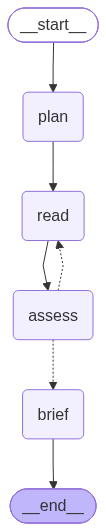

In [29]:
from IPython.display import Image
try:
    display(Image(researcher.get_graph().draw_mermaid_png()))               # the loop, drawn by the library from the edges
except Exception:
    print(researcher.get_graph().draw_mermaid())                            # the same diagram as text, if the renderer is unreachable

In [30]:
RUN_GRAPH = False                     # optional: True runs the whole agent again as a graph (about 10 minutes on a T4)
if RUN_GRAPH:
    result = researcher.invoke({"topic": SPECIFIC_TOPIC})                 # same functions, same banners; fetched PDFs are reused

Same six functions, same banners, the same budget as `research()`'s defaults (2 rounds; 4 papers, then 2). What changed is
that the loop is now a drawing, the state after every node can be saved and resumed, and a second person can read the
control flow without reading `research()`. When the shape of an agent is a cycle with a decision in it, this is the tool
built for that shape.

## Another topic

Back to arXiv: type a topic, read the banners, type the next one; an empty line or `quit` stops. Each topic takes roughly
8 minutes on a T4.

In [31]:
search = search_arxiv                                                                  # back to arXiv; another topic, 'quit' to stop
while True:
    q = input("Research topic: ").strip()
    if q.lower() in ("quit", "exit", "q", ""): break
    research(q)

Research topic: Continual learning using Lora for llms 

TOPIC: Continual learning using Lora for llms

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 1 · Plan searches (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
LoRA continual learning LLMs
adapter fine-tuning incremental LLMs
parameter efficient fine-tuning streaming LLMs
LoRA transfer learning large language models

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 2 · Find candidates · round 1
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
0.57  2019  Meta-Learning Representations for Continual Learning
0.55  2020  Energy-Based Models for Continual Learning
0.52  2018  StackNet: Stacking Parameters for Continual learning
0.51  2026  Learning Rate Matters: Vanilla LoRA May Suffice for LLM Fine-tuning
0.46  2026  Continual Learning in Transition
0.43  2020  Routing Networks with Co-training for Continual Learnin

**Problem**
Recent advanced LoRA variants claim significant performance gains, yet these improvements often rely on fixed or narrowly tuned hyperparameters. This sensitivity obscures whether vanilla LoRA is truly inferior or merely under-optimized.

**How it works**
The study systematically re-evaluates nine LoRA variants alongside vanilla LoRA by conducting extensive hyperparameter searches across learning rate, batch size, rank, and training duration. It tests these methods across diverse tasks and model scales to determine optimal configurations.

**Key results**
Once learning rates are properly tuned, all methods achieve similar peak performance (within 1-2%). While specific variants favor distinct learning rate ranges, no single method consistently outperforms others across all tasks.

**Relevance to the topic**
This research directly addresses continual learning by demonstrating that vanilla LoRA remains a competitive baseline when hyperparameters are optimized. It suggests that reported gains in newer variants may stem from specific training configurations rather than architectural superiority.

**Limitations**
Findings are limited to decoder-only LLMs (0.6B–13B parameters) and fixed secondary settings like schedulers. Results may not extend to encoder-only models, vision architectures, or untested LoRA variants.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) · LLM-Adapters: An Adapter Family for Parameter-Efficient Fine
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Full-model fine-tuning of Large Language Models (LLMs) is computationally and storage-intensive, hindering practical implementation. This necessitates efficient alternatives that avoid updating the entire model.

**How it works**
The paper introduces LLM-Adapters, a framework integrating parameter-efficient fine-tuning (PEFT) methods like LoRA, Series adapters, and Parallel adapters. These methods update only a few external parameters rather than the full model. Optimal performance is achieved by placing adapters simultaneously in Multi-head Attention and MLP layers with specific configurations, such as a rank of 32 for LoRA.

**Key results**
Smaller models with adapters outperform larger baselines on specific tasks; for instance, LLaMA-13B with LoRA achieves 65.4% accuracy on math tasks, reaching 92.8% of GPT-3.5's performance. Additionally, LLaMA-13B with LoRA surpasses GPT-3.5 (>175B) on simpler reasoning datasets like MultiArith and AddSub.

**Relevance to the topic**
This paper directly addresses continual learning via PEFT by demonstrating how adapter-based methods enable efficient task-specific fine-tuning without catastrophic forgetting of the base model, a core requirement for continual learning.

**Limitations**
The study notes that while adapters excel on simpler tasks, larger models like GPT-3.5 still generally outperform adapter-based smaller models on complex arithmetic reasoning datasets.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) · Continual Learning in Transition
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


...


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 4 · Read & summarize (model) · Energy-Based Models for Continual Learning
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


**Problem**
Continual learning faces the challenge of catastrophic forgetting, where models lose previously learned information when adapting to new tasks or data distributions. Traditional approaches often rely on external memory, growing models, or regularization, which can be inefficient or complex.

**How it works**
Instead of modifying architecture or adding memory, this method changes the training objective using Energy-Based Models (EBMs). It employs a contrastive divergence-based objective that minimizes interference with past data by adjusting the energy function. During inference, the model predicts class labels by finding the configuration that minimizes the expected energy under the current parameters.

**Key results**
The proposed EBM approach outperforms baseline methods by a large margin on several benchmarks. It achieves substantial performance boosts when combined with other continual learning techniques.

**Relevance to the topic**
While this paper does not use LoRA, it introduces a fundamental mechanism—modifying the training objective to prevent forgetting—that is highly relevant to efficient continual learning. This principle underpins modern parameter-efficient fine-tuning strategies like LoRA, which similarly aim to update model weights without disrupting prior knowledge, making the core concept of "objective modification" directly applicable to LLM continual learning.

**Limitations**
The provided text does not specify computational costs or scalability issues regarding the EBM training process itself, nor does it detail performance on large-scale language models.


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 5 · Assess coverage (model)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
gaps: ['Dynamic LoRA rank adaptation strategies for continual learning (e.g., increasing rank over time to prevent forgetting)', 'LoRA-based methods specifically designed for streaming or online continual learning scenarios (handling non-stationary data distributions in real-time)', 'Evaluation metrics and benchmarks specifically comparing LoRA continual learning performance against full fine-tuning in long-term tasks']
enough: False
new queries: ['dynamic LoRA rank adaptation continual learning', 'LoRA streaming continual learning online']

stopped: round budget reached (max_rounds=2)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
 Step 6 · Briefing (model) + citation check
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
6 papers read · about 526 words · c

### Overview
Continual learning in Large Language Models (LLMs) aims to adapt models to new tasks without losing prior knowledge, a challenge often addressed through Parameter-Efficient Fine-Tuning (PEFT) techniques like LoRA. Recent research indicates that optimizing hyperparameters can make vanilla LoRA competitive, while advanced strategies focus on initialization orthogonality or energy-based objectives to mitigate catastrophic forgetting [1][5][6].

### How the approaches work
**[1]** This study systematically re-evaluates nine LoRA variants alongside vanilla LoRA by conducting extensive hyperparameter searches across learning rate, batch size, rank, and training duration [1]. It demonstrates that once learning rates are properly tuned, all methods achieve similar peak performance, suggesting vanilla LoRA suffices when optimized rather than relying on architectural superiority [1].

**[2]** LLM-Adapters introduce a framework integrating PEFT methods like LoRA, Series adapters, and Parallel adapters, updating only a few external parameters rather than the full model [2]. Optimal performance is achieved by placing these adapters simultaneously in Multi-head Attention and MLP layers with specific configurations, such as a rank of 32 for LoRA [2].

**[3]** This survey reframes continual learning across three dimensions: *When* (spanning pre-training to inference), *Where* (extending to external harnesses like memory), and *How* (evolving to on-policy optimization) [3]. Techniques like LoRA constrain updates to low-rank subspaces or orthogonal directions, while external components manage long-term memory and test-time adaptation without holistic model modification [3].

**[4]** The study employs a three-epoch QLoRA fine-tune using 4-bit NF4 quantization and a LoRA rank of 16 to overcome hardware constraints on free-tier GPUs [4]. It utilizes an adapter-handoff recipe where only the small LoRA adapter is checkpointed and resumed on a second GPU, avoiding the transfer of large optimizer states [4].

**[5]** This method pushes orthogonality to the extreme by aligning the LoRA initialization space strictly perpendicular to pre-trained weights, disregarding the need to keep updated weights close to original values [5]. Unlike prior approaches utilizing the null space, this technique integrates input activation context into principal components to maintain knowledge integrity without relying on residual weight proximity [5].

**[6]** Instead of modifying architecture or adding memory, this method changes the training objective using Energy-Based Models (EBMs) to minimize interference with past data [6]. It employs a contrastive divergence-based objective that adjusts the energy function during training and predicts class labels by finding the configuration that minimizes expected energy during inference [6].

### Comparison

| Paper | Approach | Trade-off |
| :--- | :--- | :--- |
| [1] | Hyperparameter-optimized Vanilla LoRA | Requires extensive tuning; no single variant consistently outperforms others across all tasks [1]. |
| [2] | LLM-Adapters (Multi-layer PEFT) | Enables efficient task-specific fine-tuning but may underperform on complex reasoning compared to larger baselines [2]. |
| [3] | System-level Adaptation Framework | Provides theoretical guidance on evolution from static updates to dynamic expansion but lacks empirical validation [3]. |
| [4] | QLoRA with Adapter-Handoff | Enables low-resource training on fragmented hardware but risks quality degradation if synthetic data contains errors [4]. |
| [5] | Extreme Orthogonal Initialization | Effectively preserves pre-trained knowledge but may sacrifice weight stability compared to residual weight constraints [5]. |
| [6] | Energy-Based Models (EBMs) | Offers a fundamental mechanism to prevent forgetting via objective modification but lacks scalability details for large LLMs [6]. |

### What is still open
*   Generalization of extreme orthogonality and energy-based objectives across diverse model architectures and vision tasks remains untested [5][6].
*   The reliability of continual learning strategies heavily dependent on synthetic data quality needs further validation against real-world datasets [4].
*   Empirical benchmarks and comparative analyses for system-level adaptation frameworks are currently lacking in the literature [3].

**References**

1. Learning Rate Matters: Vanilla LoRA May Suffice for LLM Fine-tuning — https://arxiv.org/abs/2602.04998
2. LLM-Adapters: An Adapter Family for Parameter-Efficient Fine-Tuning of Large Language Models — https://arxiv.org/abs/2304.01933
3. Continual Learning in Transition — https://arxiv.org/abs/2608.06216
4. Fine-Tuning a 7B Advisor on Free-Tier GPUs: An Adapter-Handoff Recipe and a Synthetic-Data Reliability Caution — https://arxiv.org/abs/2504.15610
5. Put the Space of LoRA Initialization to the Extreme to Preserve Pre-trained Knowledge — https://arxiv.org/abs/2503.02659
6. Energy-Based Models for Continual Learning — https://arxiv.org/abs/2011.12216

Research topic: q


## Optional code challenges

1. **Budget**: run `research(SPECIFIC_TOPIC, max_rounds=1)` and `max_rounds=3`. What changed in the briefing, and what did it cost in minutes?
2. **Recency**: sort by `arxiv.SortCriterion.SubmittedDate` in `search_arxiv` and ask for recent work only. What does relevance lose?
3. **Threshold**: drop candidates below 0.4 similarity in step 2 and let the agent say "arXiv has little on this" instead of reading weak papers. Where does the message belong?
4. **Your "enough" inside the loop**: give `research()` an `assess_prompt` parameter, pass it to `assess()`, and run it with your `ENOUGH_PROMPT` from Exercise 3. Who stops the loop now?
5. **Critic in the loop**: after step 6, call `critique()` and, if it lists unsupported claims, ask the model once to rewrite the briefing without them.
6. **Drop the reference list**: in `fetch_text()`, cut the text at the last "References" heading, then run the chunk demo in section 2 again. Do the passages improve?

If you uploaded your own documents in *Your turn*, run `search = search_arxiv` first (the *Another topic* cell does).